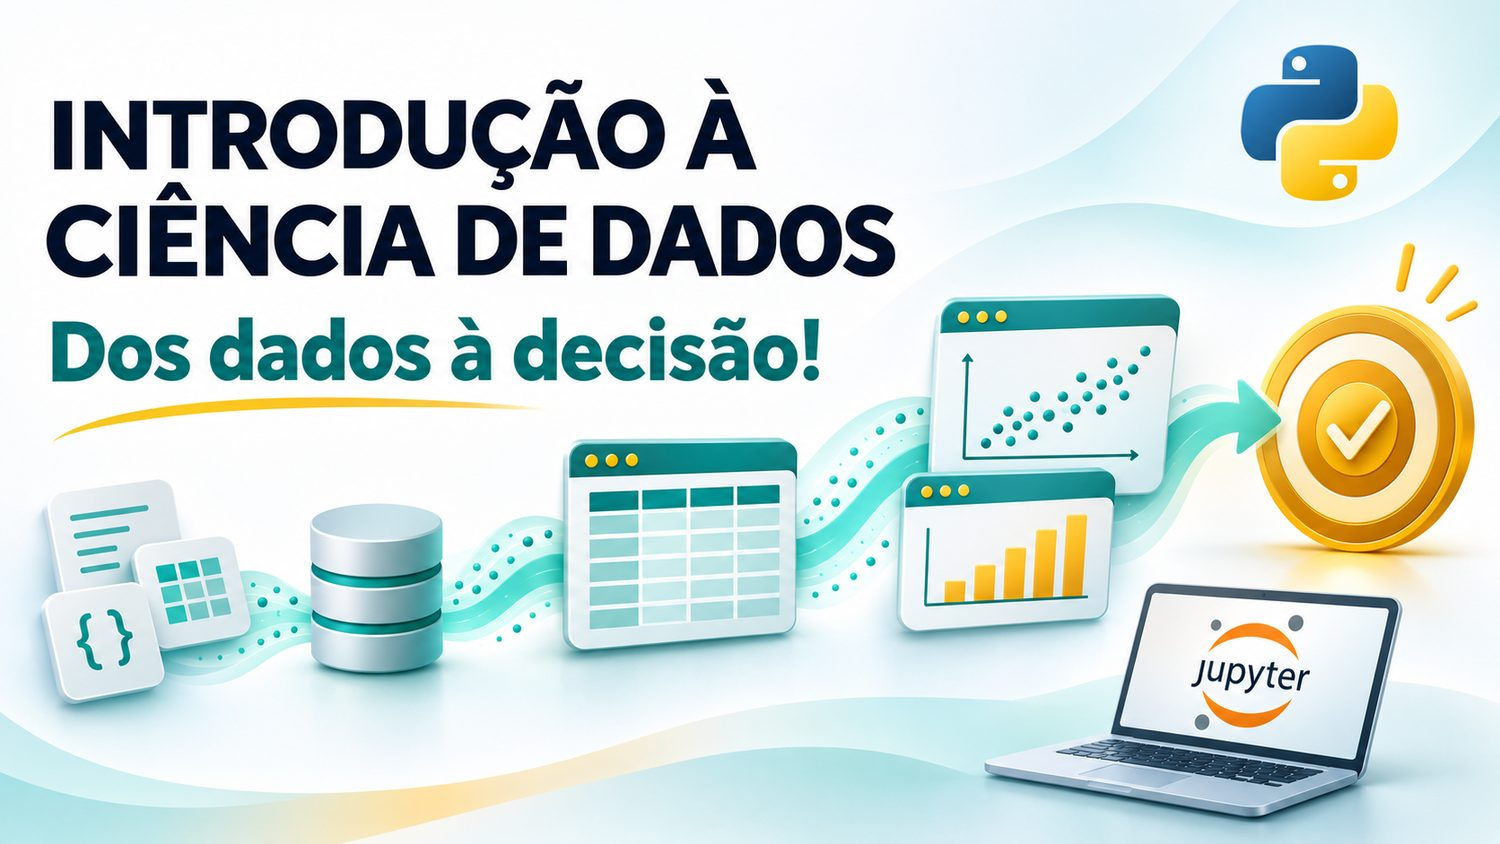

[![Abrir no Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ricardoluizdasilva/mestrado_ai_estudos/blob/main/Introdu%C3%A7%C3%A3o%20%C3%A0%20Ci%C3%AAncia%20de%20Dados/tutorial_ciencia_dados/modulo_3_explorar_os_dados/03_Medidas_Descritivas.ipynb)

# Capítulo 3 – Medidas descritivas

Resumir mil valores num só número é sempre perder informação. A arte está em escolher o número que perde menos do que interessa. Este capítulo apresenta as medidas de posição, de dispersão e de forma, e mostra em que situações cada uma engana.

> **Objetivos:** calcular e interpretar média, mediana e moda; calcular variância, desvio padrão, amplitude e amplitude interquartil; explicar porque a variância amostral divide por n − 1; ler quantis e um diagrama de caixa; reconhecer assimetria; escolher medidas robustas quando há valores extremos.

**Pré-requisitos:** capítulos 1 e 2 deste módulo. A versão com mais contas à mão está em [Estatística descritiva com Python](../../../Introdu%C3%A7%C3%A3o%20%C3%A0%20Programa%C3%A7%C3%A3o/tutorial_python/nivel_3_ia/N3_01_Estatistica_Descritiva_Python.ipynb).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Circle, FancyArrowPatch, FancyBboxPatch

# Cores usadas em todo o tutorial (sempre com o mesmo significado)
AZUL, VERDE, VIOLETA, LARANJA = "#2a78d6", "#1baf7a", "#6250d6", "#eb6834"
BOM, MAU, AVISO, CINZA, TINTA = "#0ca30c", "#d03b3b", "#fab219", "#b4bdc8", "#131c26"

plt.rcParams.update({"figure.dpi": 110, "font.size": 10, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.titleweight": "bold",
                     "axes.titlelocation": "left"})


def tela(largura, altura, tamanho=(10, 3)):
    """Cria uma figura vazia, sem eixos, para desenhar esquemas."""
    fig, ax = plt.subplots(figsize=tamanho)
    ax.set_xlim(0, largura)
    ax.set_ylim(0, altura)
    ax.axis("off")
    return fig, ax


def caixa(ax, x, y, largura, altura, texto, cor, tamanho=10, negrito=False):
    """Desenha uma caixa arredondada com texto centrado."""
    ax.add_patch(FancyBboxPatch((x, y), largura, altura, boxstyle="round,pad=0.02,rounding_size=0.1",
                                fc=cor + "30", ec=cor, lw=1.6))
    ax.text(x + largura / 2, y + altura / 2, texto, ha="center", va="center", color=TINTA,
            fontsize=tamanho, linespacing=1.45, fontweight="bold" if negrito else "normal")


def seta(ax, inicio, fim, cor="#465463", **opcoes):
    """Desenha uma seta entre dois pontos."""
    opcoes.setdefault("arrowstyle", "-|>")
    ax.add_patch(FancyArrowPatch(inicio, fim, mutation_scale=14, color=cor, lw=1.5, **opcoes))

In [2]:
def gerar_escolas(semente=11):
    """Gera o consumo diário de eletricidade de 30 escolas fictícias durante um ano letivo (dados sintéticos)."""
    rng = np.random.default_rng(semente)
    n = 30
    tipo = rng.choice(["básica", "secundária"], n, p=[0.6, 0.4])
    alunos = np.where(tipo == "básica", rng.integers(120, 520, n), rng.integers(450, 1400, n))
    escolas = pd.DataFrame({
        "escola_id": [f"E{i:02d}" for i in range(1, n + 1)],
        "tipo": tipo,
        "alunos": alunos,
        "area_m2": (alunos * rng.normal(9.0, 1.2, n)).round(-1).astype(int),
        "ano_construcao": rng.integers(1965, 2016, n),
        "paineis_solares": rng.random(n) < 0.3})
    dias = pd.date_range("2025-09-01", "2026-08-31", freq="D")
    dia_do_ano = dias.dayofyear.to_numpy()
    temperatura = 16.5 + 7.5 * np.cos(2 * np.pi * (dia_do_ano - 205) / 365) + rng.normal(0, 2.2, len(dias))
    ferias = (((dias >= "2025-12-20") & (dias <= "2026-01-04")) | ((dias >= "2026-03-28") & (dias <= "2026-04-12"))
              | (dias >= "2026-07-01"))
    meteo = pd.DataFrame({"data": dias, "temperatura": temperatura.round(1), "ferias": ferias})
    tabelas = []
    for e in escolas.itertuples():
        base = 0.55 * e.alunos + 0.012 * e.area_m2 * (1.25 if e.ano_construcao < 1990 else 1.0)
        aquecimento = 1 + 0.045 * np.clip(15 - temperatura, 0, None)
        ocupacao = np.where(dias.dayofweek >= 5, 0.22, 1.0) * np.where(ferias, 0.30, 1.0)
        sol = np.clip(0.5 + 0.5 * np.cos(2 * np.pi * (dia_do_ano - 172) / 365), 0, 1)
        solar = 1 - (0.28 * sol if e.paineis_solares else 0)
        kwh = base * aquecimento * np.maximum(ocupacao, 0.08) * solar * rng.lognormal(0, 0.10, len(dias))
        avarias = rng.random(len(dias)) < 0.004                     # dias com um consumo anormal
        kwh = np.where(avarias, kwh * rng.uniform(2.5, 4.0, len(dias)), kwh)
        tabelas.append(pd.DataFrame({"escola_id": e.escola_id, "data": dias, "kwh": kwh.round(1)}))
    return escolas, pd.concat(tabelas, ignore_index=True), meteo


escolas, consumo, meteo = gerar_escolas()
consumo.head()

,escola_id,data,kwh
0,E01,2025-09-01,300.5
1,E01,2025-09-02,264.6
2,E01,2025-09-03,265.0
3,E01,2025-09-04,270.0
4,E01,2025-09-05,303.9


## Explorar antes de concluir

A **análise exploratória de dados** (EDA, de *exploratory data analysis*) é o hábito de olhar para os dados antes de lhes aplicar um modelo. O nome vem do estatístico John Tukey, que nos anos 70 defendeu que a estatística se tinha concentrado demasiado em confirmar hipóteses e pouco em descobrir o que os dados têm para mostrar.

Explorar é fazer perguntas simples, por esta ordem:

1. Onde está o centro dos valores? (**posição**)
2. Quanto variam? (**dispersão**)
3. Que forma têm? (**assimetria**, valores extremos)
4. Como se relacionam entre si? (capítulo 5)

Vamos trabalhar com o consumo de uma escola nos dias úteis de aulas, e depois com o de todas.

In [3]:
dados = consumo.merge(meteo, on="data").merge(escolas, on="escola_id")
aulas = dados[(dados["data"].dt.dayofweek < 5) & ~dados["ferias"]]
e01 = aulas[aulas["escola_id"] == "E01"]["kwh"]
print(f"Escola E01: {len(e01)} dias úteis de aulas")

Escola E01: 197 dias úteis de aulas


## Medidas de posição

| Medida | O que é | Sensível a valores extremos? |
| --- | --- | --- |
| **Média** | A soma a dividir pelo número de valores | Muito |
| **Mediana** | O valor do meio, depois de ordenar | Pouco |
| **Moda** | O valor (ou a classe) mais frequente | Não |

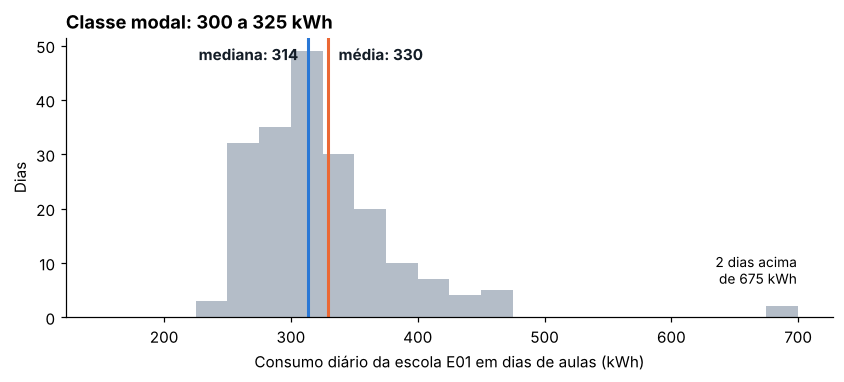

In [4]:
media, mediana = e01.mean(), e01.median()
classes = pd.cut(e01, bins=np.arange(150, 1100, 25))
moda = classes.value_counts().idxmax()

fig, ax = plt.subplots(figsize=(9, 3.3))
ax.hist(e01.clip(upper=699), bins=np.arange(150, 725, 25), color=CINZA)
topo = ax.get_ylim()[1]
ax.axvline(media, color=LARANJA, lw=2)
ax.text(media + 8, topo * 0.92, f"média: {media:.0f}", color=TINTA, fontweight="bold")
ax.axvline(mediana, color=AZUL, lw=2)
ax.text(mediana - 8, topo * 0.92, f"mediana: {mediana:.0f}", color=TINTA, fontweight="bold", ha="right")
ax.text(699, topo * 0.12, f"{int((e01 >= 675).sum())} dias acima\nde 675 kWh", ha="right", fontsize=9)
ax.set_xlabel("Consumo diário da escola E01 em dias de aulas (kWh)")
ax.set_ylabel("Dias")
ax.set_title(f"Classe modal: {moda.left:.0f} a {moda.right:.0f} kWh")
plt.show()

A maior parte dos dias fica entre 200 e 400 kWh, mas há uma **cauda** à direita: alguns dias frios, e um ou outro dia anormal muito acima. Essa cauda puxa a média para cima; a mediana quase não se mexe.

### Um só valor chega para mudar a média

In [5]:
normal = e01[e01 < e01.quantile(0.99)].sample(20, random_state=1).round().to_numpy()
com_erro = np.append(normal[:-1], normal[-1] * 100)            # o último valor com dois zeros a mais

for nome, valores in [("Vinte dias normais", normal), ("Com um erro de registo", com_erro)]:
    print(f"{nome:<24} média: {valores.mean():>8.1f}   mediana: {np.median(valores):>6.1f}")

Vinte dias normais       média:    321.8   mediana:  314.5
Com um erro de registo   média:   1787.0   mediana:  318.5


Um erro em vinte valores multiplicou a média por mais de cinco. A mediana passou de 314,5 para 318,5. Diz-se que a mediana é uma medida **robusta**: aguenta valores extremos sem se alterar.

Isto não faz da mediana a melhor escolha em todos os casos. Se a pergunta for «quanto vamos pagar no total?», a média é que interessa, porque o total é a média vezes o número de dias, com os dias anormais incluídos.

> **Regra prática:** calcula sempre as duas. Se a média e a mediana forem próximas, a distribuição é mais ou menos simétrica e tanto faz. Se forem diferentes, há uma cauda ou valores extremos, e vale a pena ir ver porquê.

## Medidas de dispersão

Duas escolas com a mesma média podem ser muito diferentes: numa, todos os dias são parecidos; noutra, há dias baixos e dias altíssimos.

| Medida | O que é | Unidade | Robusta? |
| --- | --- | --- | --- |
| **Amplitude** | Máximo − mínimo | a dos dados | Não |
| **Variância** | Média dos quadrados dos desvios em relação à média | o quadrado da dos dados | Não |
| **Desvio padrão** | Raiz quadrada da variância | a dos dados | Não |
| **Amplitude interquartil (AIQ)** | 3.º quartil − 1.º quartil | a dos dados | Sim |
| **Coeficiente de variação** | Desvio padrão ÷ média | sem unidade | Não |

In [6]:
q1, q3 = e01.quantile([0.25, 0.75])
print(f"Amplitude:               {e01.max() - e01.min():.0f} kWh")
print(f"Variância:               {e01.var():.0f} kWh²")
print(f"Desvio padrão:           {e01.std():.0f} kWh")
print(f"Amplitude interquartil:  {q3 - q1:.0f} kWh  (de {q1:.0f} a {q3:.0f})")
print(f"Coeficiente de variação: {e01.std() / e01.mean():.0%}")

Amplitude:               932 kWh
Variância:               8641 kWh²
Desvio padrão:           93 kWh
Amplitude interquartil:  61 kWh  (de 288 a 349)
Coeficiente de variação: 28%


O **desvio padrão** é a medida mais usada porque está na unidade dos dados e lê-se como «a distância típica à média». O **coeficiente de variação** serve para comparar a dispersão de grupos com médias muito diferentes: um desvio de 50 kWh é enorme numa escola que gasta 150 e irrelevante numa que gasta 900.

### Porque se divide por n − 1

A variância de uma amostra calcula-se dividindo a soma dos quadrados dos desvios por **n − 1**, e não por n. A razão é que os desvios se medem em relação à média **da própria amostra**, que fica sempre mais perto dos valores da amostra do que a verdadeira média da população. Dividir por n daria, em média, uma variância demasiado pequena.

Uma simulação mostra o efeito.

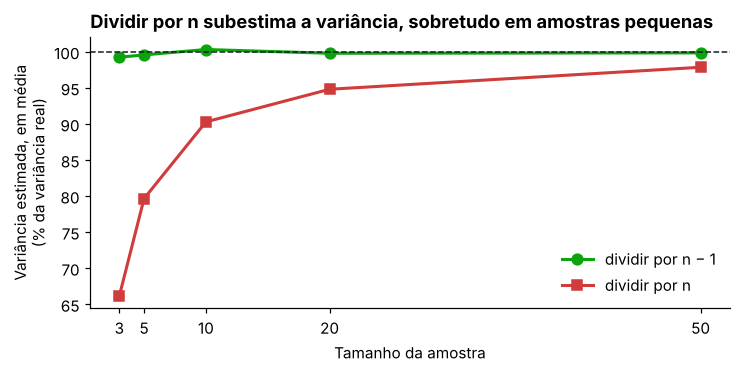

In [7]:
rng = np.random.default_rng(0)
populacao = aulas["kwh"].to_numpy()
variancia_real = populacao.var()                       # a população inteira: divide-se por n

tamanhos = [3, 5, 10, 20, 50]
por_n, por_n_menos_1 = [], []
for n in tamanhos:
    amostras = rng.choice(populacao, (20000, n))
    por_n.append(amostras.var(axis=1, ddof=0).mean() / variancia_real * 100)
    por_n_menos_1.append(amostras.var(axis=1, ddof=1).mean() / variancia_real * 100)

fig, ax = plt.subplots(figsize=(7.5, 3.2))
ax.plot(tamanhos, por_n_menos_1, color=BOM, lw=2, marker="o", ms=7, label="dividir por n − 1")
ax.plot(tamanhos, por_n, color=MAU, lw=2, marker="s", ms=7, label="dividir por n")
ax.axhline(100, color=TINTA, ls="--", lw=1)
ax.legend(frameon=False, loc="lower right")
ax.set_xticks(tamanhos)
ax.set_xlabel("Tamanho da amostra")
ax.set_ylabel("Variância estimada, em média\n(% da variância real)")
ax.set_title("Dividir por n subestima a variância, sobretudo em amostras pequenas")
plt.show()

Com amostras de três valores, dividir por n dá em média dois terços da variância real. Dividir por n − 1 corrige o erro em todos os tamanhos. Com amostras grandes, a diferença deixa de ter importância.

Atenção às bibliotecas, que não fazem todas o mesmo por omissão:

| Função | Divide por | Para mudar |
| --- | --- | --- |
| `Series.var()` e `Series.std()` do pandas | n − 1 | `ddof=0` |
| `np.var()` e `np.std()` do NumPy | n | `ddof=1` |

## Quantis e o diagrama de caixa

Um **quantil** é o valor abaixo do qual fica uma dada fração dos dados. Os mais usados são os **quartis**, que dividem os dados em quatro partes iguais: o 1.º quartil (25%), a mediana (50%) e o 3.º quartil (75%).

O **diagrama de caixa**, também inventado por Tukey, desenha cinco números de uma vez.

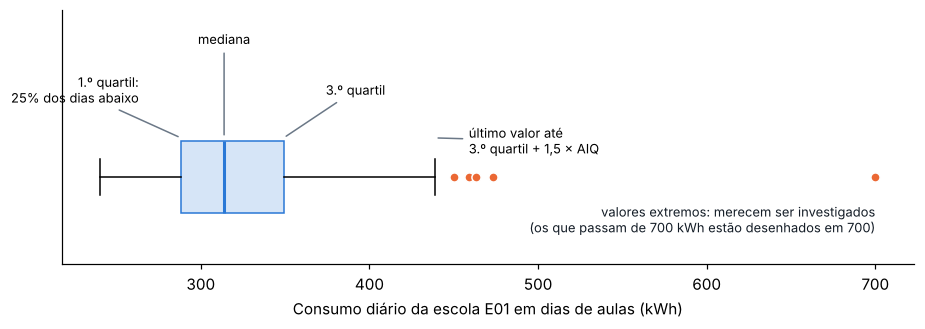

Dias assinalados como extremos: 7 de 197


In [8]:
fig, ax = plt.subplots(figsize=(10, 3))
caixa_ = ax.boxplot(e01.clip(upper=700), orientation="horizontal", widths=0.5, patch_artist=True,
                    boxprops={"facecolor": AZUL + "30", "edgecolor": AZUL}, medianprops={"color": AZUL, "linewidth": 2},
                    flierprops={"marker": "o", "markerfacecolor": LARANJA, "markeredgecolor": "white", "markersize": 6})
aiq = q3 - q1
limite = q3 + 1.5 * aiq
bigode = e01[e01 <= limite].max()
anotacoes = [(q1, q1 - 25, 1.6, "right", "1.º quartil:\n25% dos dias abaixo"), (mediana, mediana, 1.95, "center", "mediana"),
             (q3, q3 + 25, 1.6, "left", "3.º quartil"), (bigode, bigode + 20, 1.25, "left", "último valor até\n3.º quartil + 1,5 × AIQ")]
for x, x_texto, y_texto, alinhamento, texto in anotacoes:
    ax.annotate(texto, (x, 1.27), (x_texto, y_texto), ha=alinhamento, va="center", fontsize=8.5,
                arrowprops={"arrowstyle": "-", "color": "#6b7887"})
ax.text(700, 0.62, "valores extremos: merecem ser investigados\n(os que passam de 700 kWh estão desenhados em 700)", ha="right", fontsize=8.5, color=TINTA)
ax.set_ylim(0.4, 2.15)
ax.set_yticks([])
ax.set_xlabel("Consumo diário da escola E01 em dias de aulas (kWh)")
plt.show()

print(f"Dias assinalados como extremos: {(e01 > limite).sum()} de {len(e01)}")

A caixa contém a metade central dos dias. Os «bigodes» vão até ao último valor dentro de 1,5 vezes a amplitude interquartil. O que fica para lá é assinalado ponto a ponto.

Um valor assinalado **não é automaticamente um erro**. É um valor que merece uma pergunta: foi uma avaria, um evento na escola, um dia de frio invulgar, um engano de registo? A resposta decide o que fazer com ele (módulo 2, capítulo 4).

### Comparar grupos com caixas

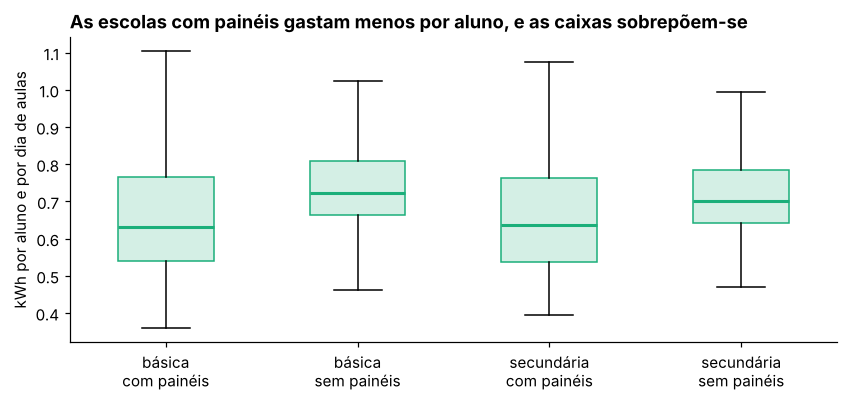

,count,mean,std,25%,50%,75%
grupo,,,,,,
básica\ncom painéis,1970.0,0.669,0.206,0.540,0.632,0.765
básica\nsem painéis,1773.0,0.748,0.139,0.664,0.722,0.809
secundária\ncom painéis,394.0,0.667,0.191,0.538,0.636,0.762
secundária\nsem painéis,1773.0,0.727,0.150,0.643,0.702,0.784


In [9]:
aulas = aulas.assign(kwh_por_aluno=aulas["kwh"] / aulas["alunos"],
                     grupo=aulas["tipo"] + np.where(aulas["paineis_solares"], "\ncom painéis", "\nsem painéis"))
grupos = sorted(aulas["grupo"].unique())

fig, ax = plt.subplots(figsize=(9, 3.6))
ax.boxplot([aulas[aulas["grupo"] == g]["kwh_por_aluno"] for g in grupos], widths=0.5, patch_artist=True, showfliers=False,
           boxprops={"facecolor": VERDE + "30", "edgecolor": VERDE}, medianprops={"color": VERDE, "linewidth": 2})
ax.set_xticks(range(1, len(grupos) + 1), grupos)
ax.set_ylabel("kWh por aluno e por dia de aulas")
ax.set_title("As escolas com painéis gastam menos por aluno, e as caixas sobrepõem-se")
plt.show()

aulas.groupby("grupo")["kwh_por_aluno"].describe()[["count", "mean", "std", "25%", "50%", "75%"]].round(3)

As medianas das escolas com painéis são mais baixas, mas as caixas sobrepõem-se bastante: há muitos dias em que uma escola com painéis gasta mais do que uma sem painéis. Uma diferença entre médias não quer dizer que **todos** os casos de um grupo estejam abaixo dos do outro.

`describe()` dá de uma vez as medidas mais usadas. É o primeiro comando a correr numa tabela nova.

## Assimetria

Uma distribuição é **simétrica** quando os valores se espalham por igual para os dois lados do centro, e **assimétrica** quando tem uma cauda mais comprida de um lado.

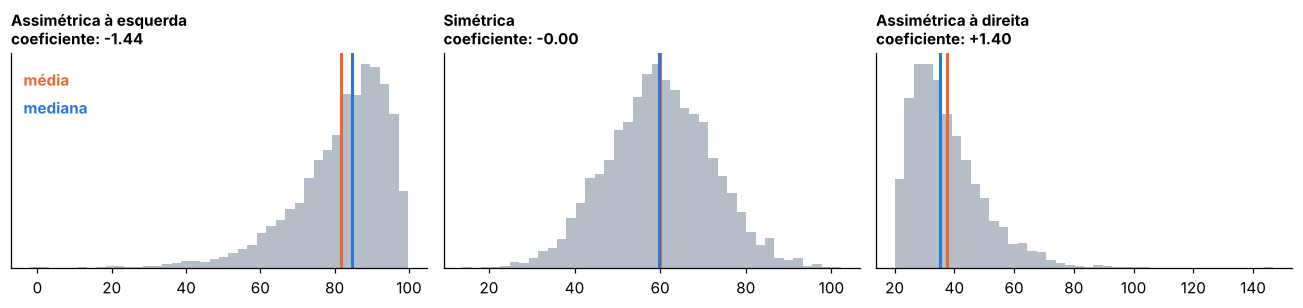

In [10]:
rng = np.random.default_rng(2)
exemplos = [("Assimétrica à esquerda", 100 - rng.gamma(2.0, 9, 4000)), ("Simétrica", rng.normal(60, 12, 4000)),
            ("Assimétrica à direita", 20 + rng.gamma(2.0, 9, 4000))]

fig, eixos = plt.subplots(1, 3, figsize=(12, 2.9))
for ax, (nome, valores) in zip(eixos, exemplos):
    serie = pd.Series(valores)
    ax.hist(valores, bins=40, color=CINZA)
    ax.axvline(serie.mean(), color=LARANJA, lw=2)
    ax.axvline(serie.median(), color=AZUL, lw=2)
    ax.set_title(f"{nome}\ncoeficiente: {serie.skew():+.2f}", fontsize=10)
    ax.set_yticks([])
eixos[0].text(0.03, 0.85, "média", color=LARANJA, fontweight="bold", transform=eixos[0].transAxes)
eixos[0].text(0.03, 0.72, "mediana", color=AZUL, fontweight="bold", transform=eixos[0].transAxes)
plt.tight_layout()
plt.show()

A média é sempre arrastada para o lado da cauda. O **coeficiente de assimetria** (`skew`) resume a forma num número: perto de zero para distribuições simétricas, positivo com cauda à direita, negativo com cauda à esquerda.

Rendimentos, preços de casas, tempos de espera e consumos são quase sempre assimétricos à direita: não podem ser negativos, e nada impede que alguns valores sejam muito altos. Nestes casos, a mediana descreve melhor o caso típico.

In [11]:
print(f"Consumo em dias de aulas, todas as escolas: assimetria = {aulas['kwh'].skew():.2f}")
print(f"Média: {aulas['kwh'].mean():.0f} kWh   Mediana: {aulas['kwh'].median():.0f} kWh")

Consumo em dias de aulas, todas as escolas: assimetria = 1.46
Média: 347 kWh   Mediana: 294 kWh


## Um resumo engana quando mistura grupos

Até aqui olhámos só para os dias de aulas. Se resumirmos o ano inteiro de uma escola, acontece outra coisa.

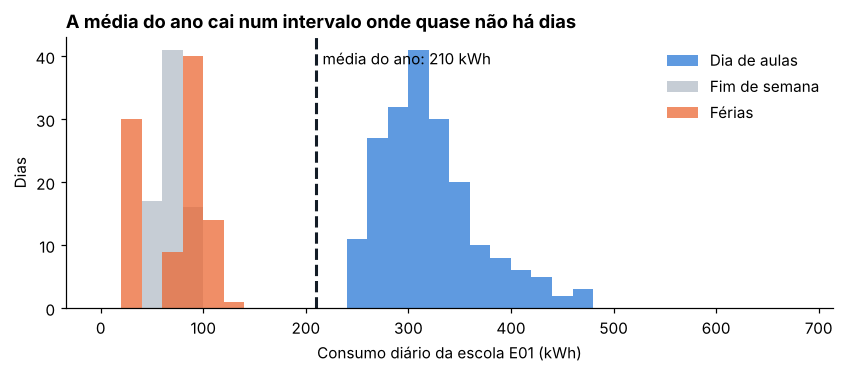

In [12]:
ano_e01 = dados[dados["escola_id"] == "E01"]
situacao = np.select([ano_e01["ferias"], ano_e01["data"].dt.dayofweek >= 5], ["Férias", "Fim de semana"], "Dia de aulas")

fig, ax = plt.subplots(figsize=(9, 3.2))
limites = np.arange(0, 700, 20)
for nome, cor in [("Dia de aulas", AZUL), ("Fim de semana", CINZA), ("Férias", LARANJA)]:
    ax.hist(ano_e01["kwh"][situacao == nome].clip(upper=690), bins=limites, color=cor, alpha=0.75, label=nome)
ax.axvline(ano_e01["kwh"].mean(), color=TINTA, lw=2, ls="--")
ax.text(ano_e01["kwh"].mean() + 6, ax.get_ylim()[1] * 0.9, f"média do ano: {ano_e01['kwh'].mean():.0f} kWh")
ax.set_xlabel("Consumo diário da escola E01 (kWh)")
ax.set_ylabel("Dias")
ax.legend(frameon=False)
ax.set_title("A média do ano cai num intervalo onde quase não há dias")
plt.show()

A distribuição tem **dois picos**: os dias com a escola fechada e os dias de aulas. A média do ano fica entre os dois, num valor que quase nunca acontece. Nenhuma medida de posição resume bem uma mistura de grupos diferentes.

> **Antes de resumir, olha para a distribuição.** Se tiver mais de um pico, há grupos misturados: separa-os e resume cada um.

## Exercícios

### `Exercício 1` – Média ou mediana?

Que medida usarias em cada caso, e porquê?

1. O salário «típico» numa empresa com 40 trabalhadores e três administradores.
2. O consumo total de eletricidade previsto para o próximo ano.
3. O tempo de espera numa urgência hospitalar.
4. A altura dos alunos de uma turma.

<details>
<summary><b>Ver uma solução possível</b></summary>

1. Mediana: os três salários mais altos puxam a média para um valor que quase ninguém recebe.
2. Média: o total é a média vezes o número de dias.
3. Mediana, acompanhada de um quantil alto (por exemplo, o percentil 90): o que preocupa são as esperas longas.
4. Tanto faz: as alturas são quase simétricas.

</details>

### `Exercício 2` – Cinco números

Calcula, para a escola `E12` em dias de aulas, o mínimo, os três quartis e o máximo. Quantos dias ficam acima de 3.º quartil + 1,5 × AIQ? Mostra-os.

In [13]:
# Escreve aqui o código do exercício 2

<details>
<summary><b>Ver uma solução possível</b></summary>

```python
e12 = aulas[aulas["escola_id"] == "E12"]
print(e12["kwh"].quantile([0, 0.25, 0.5, 0.75, 1]).round(1))
q1_, q3_ = e12["kwh"].quantile([0.25, 0.75])
extremos = e12[e12["kwh"] > q3_ + 1.5 * (q3_ - q1_)]
print(len(extremos), "dias extremos")
extremos[["data", "kwh", "temperatura"]]
```

Alguns dos dias assinalados são dias frios, em que o consumo alto tem explicação. Os que não são frios e têm o dobro ou o triplo do consumo habitual são os que vale a pena investigar.

</details>

### `Exercício 3` – Comparar a dispersão

Qual das escolas tem o consumo mais irregular em dias de aulas? Calcula o desvio padrão e o coeficiente de variação de cada escola e compara as duas ordenações.

In [14]:
# Escreve aqui o código do exercício 3

<details>
<summary><b>Ver uma solução possível</b></summary>

```python
t = aulas.groupby("escola_id")["kwh"].agg(media="mean", desvio="std")
t["cv"] = t["desvio"] / t["media"]
print(t.sort_values("desvio", ascending=False).head(3).round(2))
print(t.sort_values("cv", ascending=False).head(3).round(2))
```

Pelo desvio padrão, as mais irregulares são as escolas maiores, só porque gastam mais. O coeficiente de variação tira o efeito da dimensão e mostra as escolas cujo consumo varia mais em proporção.

</details>

### `Exercício 4` – n ou n − 1?

Calcula o desvio padrão dos valores `[210, 250, 230]` com `np.std` e com `pd.Series(...).std()`. Porque dão resultados diferentes, e qual está certo?

In [15]:
# Escreve aqui o código do exercício 4

<details>
<summary><b>Ver uma solução possível</b></summary>

```python
valores = [210, 250, 230]
print(np.std(valores), pd.Series(valores).std(), np.std(valores, ddof=1))
```

O NumPy divide por n (16,3) e o pandas por n − 1 (20,0). Nenhum está errado: depende do que os três valores são. Se forem **todos** os dias que interessam, divide-se por n. Se forem uma amostra de um período maior, que é o caso mais frequente, divide-se por n − 1.

</details>

## Verifica o que aprendeste

- [ ] Sei calcular média, mediana e moda, e dizer quando cada uma engana.
- [ ] Sei o que é uma medida robusta.
- [ ] Sei calcular e interpretar a variância, o desvio padrão, a amplitude interquartil e o coeficiente de variação.
- [ ] Sei explicar porque a variância amostral divide por n − 1.
- [ ] Sei ler um diagrama de caixa.
- [ ] Sei reconhecer uma distribuição assimétrica e o efeito que tem na média.
- [ ] Sei porque se olha para a distribuição antes de a resumir.

## Leitura recomendada

- https://en.wikipedia.org/wiki/Exploratory_data_analysis
- https://en.wikipedia.org/wiki/Box_plot
- https://en.wikipedia.org/wiki/Bessel%27s_correction
- https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.describe.html